# XXZ模型：Trotter分解（量子回路）

XXZ模型のNéel状態$\ket{0101\cdots}$からのスタッガード磁化$m_s(t)$を、Trotter分解した量子回路で求める。以下ではQiskitで回路を組み、状態ベクトルシミュレータで計算する。手法の一般論は [methods/03_trotter.ipynb](../../methods/03_trotter.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と XXZ 模型の定義（src/qmb/models.py）
from qmb.operators import neel_state
from qmb.ed import time_evolve_expectation
from qmb.models import xxz_hamiltonian as hamiltonian, staggered_magnetization
from qiskit.quantum_info import Statevector

# XXZ 模型の Trotter 回路（src/qmb/circuits.py）
#   xxz_op, staggered_op : H と M_s を Pauli 演算子の和（SparsePauliOp）で表したもの
#   neel_circuit         : Néel 状態 |0101...> を作る回路
#   xxz_trotter_step     : Trotter分解の1ステップ（order=1 または 2）
#   ms_trotter           : Trotter分解で m_s(t) を計算
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_trotter_step??）
from qmb.circuits import xxz_op, staggered_op, neel_circuit, xxz_trotter_step, ms_trotter

## 1. ハミルトニアンの分け方と回路

- **同じボンドの3つの項は交換する**

  1本のボンドの項$h_j = J(X_jX_{j+1} + Y_jY_{j+1} + \Delta Z_jZ_{j+1})$の中では、たとえば$X_jX_{j+1}$と$Y_jY_{j+1}$は量子ビット$j$と$j+1$の2箇所でぶつかるので交換する（[methods/03_trotter.ipynb](../../methods/03_trotter.ipynb)の2節）。$ZZ$との組も同様なので、3つの項はすべて交換し
  \begin{equation}
  e^{-ih_j\tau} = e^{-iJ\tau X_jX_{j+1}}e^{-iJ\tau Y_jY_{j+1}}e^{-iJ\Delta\tau Z_jZ_{j+1}} = R_{XX}(2J\tau)\,R_{YY}(2J\tau)\,R_{ZZ}(2J\Delta\tau)
  \end{equation}
  と、ちょうど分解できる。ここで$R_{PP}(\theta) = e^{-i\frac{\theta}{2}P\otimes P}$はQiskitの標準ゲートである。

- **隣り合うボンドは交換しない**

  隣り合うボンドの項は量子ビット1個を共有し、そこで異なるPauliがぶつかる。たとえば
  \begin{equation}
  [X_0X_1,\ Y_1Y_2] = X_0[X_1, Y_1]Y_2 = 2i\,X_0Z_1Y_2 \neq 0
  \end{equation}
  である。そこで、量子ビットを共有しない**偶数番目のボンドと奇数番目のボンド**に分ける。
  \begin{equation}
  H = H_{\mathrm{even}} + H_{\mathrm{odd}},\quad H_{\mathrm{even}} = \sum_{j\,\text{偶数}}h_j,\quad H_{\mathrm{odd}} = \sum_{j\,\text{奇数}}h_j
  \end{equation}
  各グループの中のボンドは互いに重ならないので交換し、$e^{-iH_{\mathrm{even}}\delta t} = \prod_{j\,\text{偶数}}e^{-ih_j\delta t}$は厳密である。近似が入るのは$H_{\mathrm{even}}$と$H_{\mathrm{odd}}$の間だけで、1次の分解の1ステップは$e^{-iH_{\mathrm{odd}}\delta t}e^{-iH_{\mathrm{even}}\delta t}$である。

  TFIMでは「相互作用の項」と「磁場の項」という**項の種類**で2つに分けたが、XXZ模型では**場所**（偶奇のボンド）で分ける。

- **回路の大きさ**

  1ステップは「偶数ボンドの2量子ビットゲートの層」と「奇数ボンドの層」の2層で、どちらも並列にかけられるので、深さは$n$によらない。各ボンドのゲート$e^{-ih_j\tau}$は$R_{XX}R_{YY}R_{ZZ}$の3つで書いたが、任意の2量子ビットゲートはCNOT 3個と1量子ビットゲートで作れるので、実機では1ボンドあたりCNOT 3個になる。

- **全磁化の保存**

  各ボンドのゲート$e^{-ih_j\tau}$は$h_j$の指数関数なので、$h_j$と同じく$Z_j + Z_{j+1}$を保存する。したがってTrotter分解した回路も**全磁化を厳密に保存する**（Trotter誤差があっても$\sum_jZ_j$は変わらない）。実機では、測定結果の$\sum_jZ_j$が初期値と違うショットを捨てる（ポストセレクション）ことで、ノイズの一部を取り除ける。

- **初期状態と測定**

  Néel状態$\ket{0101\cdots}$は、$\ket{0\cdots0}$の奇数番目の量子ビットに$X$ゲートをかければ作れる。$M_s = \frac{1}{n}\sum_j(-1)^jZ_j$は$Z$基底でそのまま測れる（TFIMの$m_x$のように測定の前に$H$ゲートをかける必要がない）。結果のビット$b_j$から$Z_j = 1 - 2b_j$を作り、$(-1)^j$をつけて平均すればよい。

## 2. この模型でのTrotter誤差の特徴

- **交換子**：$[H_{\mathrm{even}}, H_{\mathrm{odd}}]$は、隣り合うボンドの組ごとに$X_0Z_1Y_2$のような3サイトの項を作る。組の数は$\approx n$なので、TFIMと同じく$n$が大きいほど誤差の上界は大きくなる。

- **1次と2次の分解の関係**

  2次の分解の1ステップは$e^{-iH_{\mathrm{even}}\delta t/2}e^{-iH_{\mathrm{odd}}\delta t}e^{-iH_{\mathrm{even}}\delta t/2}$である。$E_\tau = e^{-iH_{\mathrm{even}}\tau}$、$O = e^{-iH_{\mathrm{odd}}\delta t}$と書くと、$r$回繰り返したときに隣り合う$E_{\delta t/2}$がくっついて
  \begin{equation}
  \left(E_{\delta t/2}\,O\,E_{\delta t/2}\right)^r = E_{\delta t/2}\left(O\,E_{\delta t}\right)^rE_{-\delta t/2}
  \end{equation}
  と、1次の分解$(OE_{\delta t})^r$の両側に$E_{\pm\delta t/2}$をつけた形になる。

  TFIMでは、初期状態$\ket{+\cdots+}$が右端の$e^{-iH_X\delta t/2}$の固有状態で、左端は観測量と交換したので、1次と2次で$m_x$が完全に一致した（[01_tfim/03_trotter.ipynb](../01_tfim/03_trotter.ipynb)の2節）。XXZ模型では、Néel状態は$H_{\mathrm{even}}$の固有状態ではなく（$XY$項が$\ket{01}\to\ket{10}$と移す）、$M_s$も$H_{\mathrm{even}}$と交換しないので、**1次と2次の結果は異なる**。

  上の式は、1次の分解の誤差が「2次の分解の誤差（$O(\delta t^2)$で、時間とともに積み重なる）」と「最初と最後の$E_{\pm\delta t/2}$のずれ（$O(\delta t)$で、時間とともに積み重ならない）」の和であることを示している。したがって1次の分解の$m_s$の誤差は、$\delta t$が大きいうちは$O(\delta t^2)$のように見え、$\delta t$を小さくしていくと$O(\delta t)$の項が残る（[12_staggered_magnetization.ipynb](12_staggered_magnetization.ipynb)の4節で確かめる）。

## 3. $n=2$の手計算

$n=2$（開放境界）の場合を手で計算する。

- **Trotter誤差がない**

  ボンドが$(0,1)$の1本しかないので、$H = H_{\mathrm{even}}$、$H_{\mathrm{odd}} = 0$である。1節より$e^{-iH\tau} = R_{XX}(2J\tau)R_{YY}(2J\tau)R_{ZZ}(2J\Delta\tau)$は厳密なので、**$\delta t$をどれだけ大きくしても誤差がない**。

- **有効1スピンでの確認**

  Néel状態$\ket{01}$から出発すると、状態は$\{\ket{01}, \ket{10}\}$の2次元部分空間から出ない（全磁化の保存）。この部分空間で
  $$
  X_0X_1\ket{01} = \ket{10},\quad Y_0Y_1\ket{01} = (i\ket{1})(-i\ket{0}) = \ket{10},\quad Z_0Z_1\ket{01} = -\ket{01}
  $$
  （$\ket{10}$についても同様）なので、$\ket{01}$を$\ket{0}$、$\ket{10}$を$\ket{1}$とみなした有効スピンのPauli行列$\sigma$を使うと
  $$
  X_0X_1 = Y_0Y_1 = \sigma_x,\quad Z_0Z_1 = -1,\quad M_s = \sigma_z
  $$
  と書ける。よって1ステップのゲートは
  $$
  R_{XX}(2J\tau)R_{YY}(2J\tau)R_{ZZ}(2J\Delta\tau) = e^{-iJ\tau\sigma_x}e^{-iJ\tau\sigma_x}e^{iJ\Delta\tau} = e^{iJ\Delta\tau}\,e^{-2iJ\tau\sigma_x}
  $$
  で、全体の位相を除くと$x$軸まわりの角度$4J\tau$の回転である。$z$方向を向いた初期状態$\ket{0}_{\mathrm{eff}}$を$x$軸まわりに回すと$\langle\sigma_z\rangle = \cos(4J\tau)$なので、$r$ステップ後（$t = r\delta t$）も
  $$
  m_s(t) = \cos(4Jt)
  $$
  となり、厳密対角化の手計算と一致する。$R_{XX}$と$R_{YY}$がこの部分空間で同じ回転として働き、角度が足し合わされることがわかる。$R_{ZZ}$は位相をつけるだけなので、$\Delta$は結果に現れない。

## 4. コードで確かめる

Qiskitで回路を組んで計算する。回路を作る関数は `src/qmb/circuits.py` にまとめてあり、ノートブック冒頭で読み込んでいる。Qiskitは量子ビットの並びが厳密対角化で使った`np.kron`と逆順だが、演算子もゲートも量子ビット$j$＝サイト$j$として指定しているので、サイトごとの符号$(-1)^j$を含む$M_s$もそのまま比較できる。

In [2]:
# Trotter分解の1ステップの回路（n=4）
print(xxz_trotter_step(4, 1.0, 0.5, 0.1).draw())

     ┌───────────┐┌───────────┐                                              
q_0: ┤0          ├┤0          ├─■────────────────────────────────────────────
     │  Rxx(0.2) ││  Ryy(0.2) │ │ZZ(0.1) ┌───────────┐┌───────────┐          
q_1: ┤1          ├┤1          ├─■────────┤0          ├┤0          ├─■────────
     ├───────────┤├───────────┤          │  Rxx(0.2) ││  Ryy(0.2) │ │ZZ(0.1) 
q_2: ┤0          ├┤0          ├─■────────┤1          ├┤1          ├─■────────
     │  Rxx(0.2) ││  Ryy(0.2) │ │ZZ(0.1) └───────────┘└───────────┘          
q_3: ┤1          ├┤1          ├─■────────────────────────────────────────────
     └───────────┘└───────────┘                                              


δt = 0.3: 手計算との最大誤差 = 2.3e-15
δt = 0.03: 手計算との最大誤差 = 7.0e-15


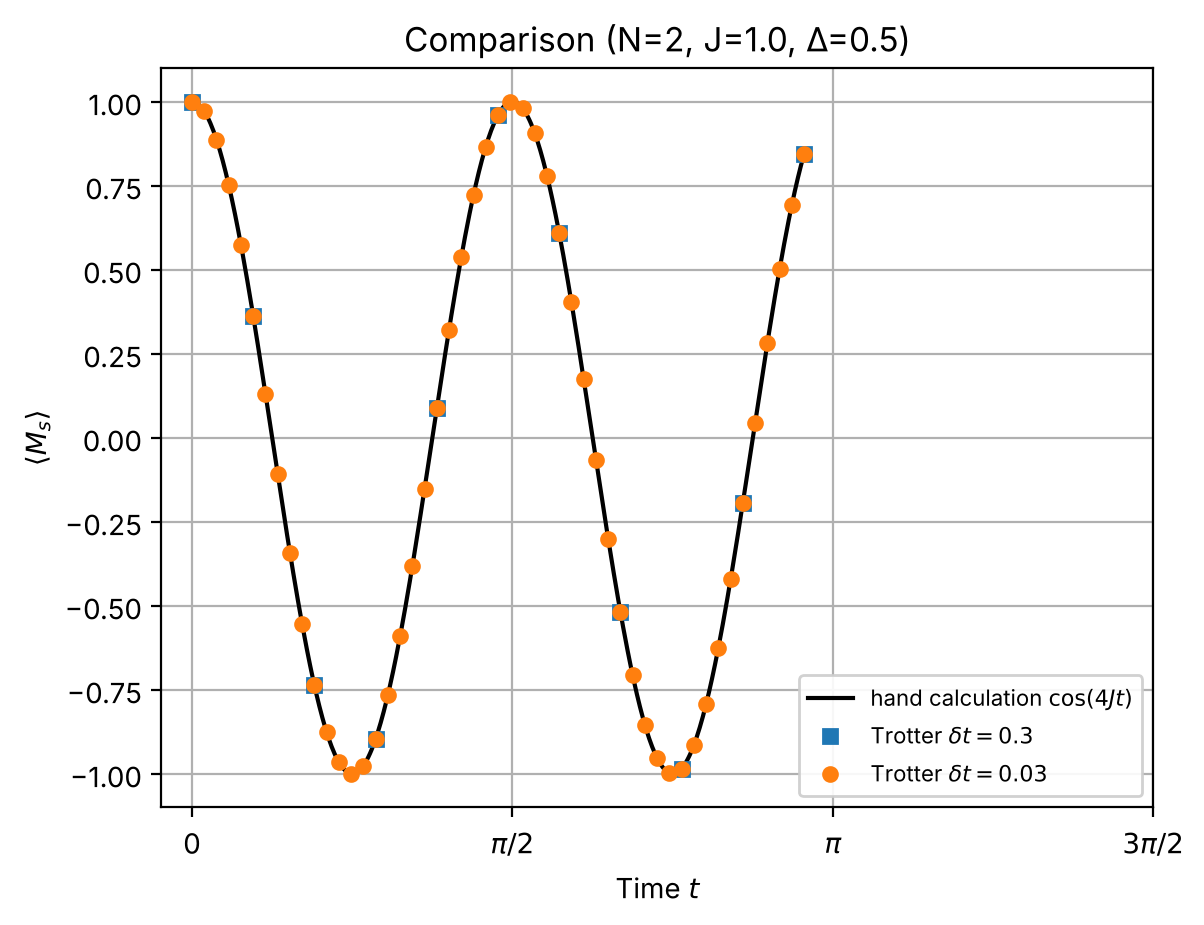

In [3]:
# 例: N=2, J=1, Δ=0.5。時間刻みを大きくしても手計算と一致する
N = 2
J = 1.0
Delta = 0.5
t_max = 3

ts_fine = np.linspace(0, t_max, 400)
T = np.pi / 2
plt.plot(ts_fine, np.cos(4 * J * ts_fine), "k-", label=r"hand calculation $\cos(4Jt)$")
for r, mk in [(10, "s"), (100, "o")]:
    ts_r, ms_r = ms_trotter(N, J, Delta, t_max, r)
    print(f"δt = {t_max / r}: 手計算との最大誤差 = {np.max(np.abs(ms_r - np.cos(4 * J * ts_r))):.1e}")
    every = max(1, r // 50)
    plt.plot(ts_r[::every], ms_r[::every], mk, ms=5, label=rf"Trotter $\delta t={t_max / r}$")
plt.xticks([k * T for k in range(4)], ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J}, Δ={Delta})")
plt.legend(loc="lower right", fontsize=8, framealpha=0.9)
plt.grid()
plt.show()

$\delta t = 0.3$でも誤差は数値誤差の範囲で、$n=2$ではTrotter誤差がないことが確かめられた。

ボンドが2本以上になる$n=4$では、偶数ボンドと奇数ボンドが交換しないのでTrotter誤差が現れ、1次と2次の分解で結果が異なる。

1次 (δt = 0.3): 最大誤差 = 1.14e-01
2次 (δt = 0.3): 最大誤差 = 1.59e-01


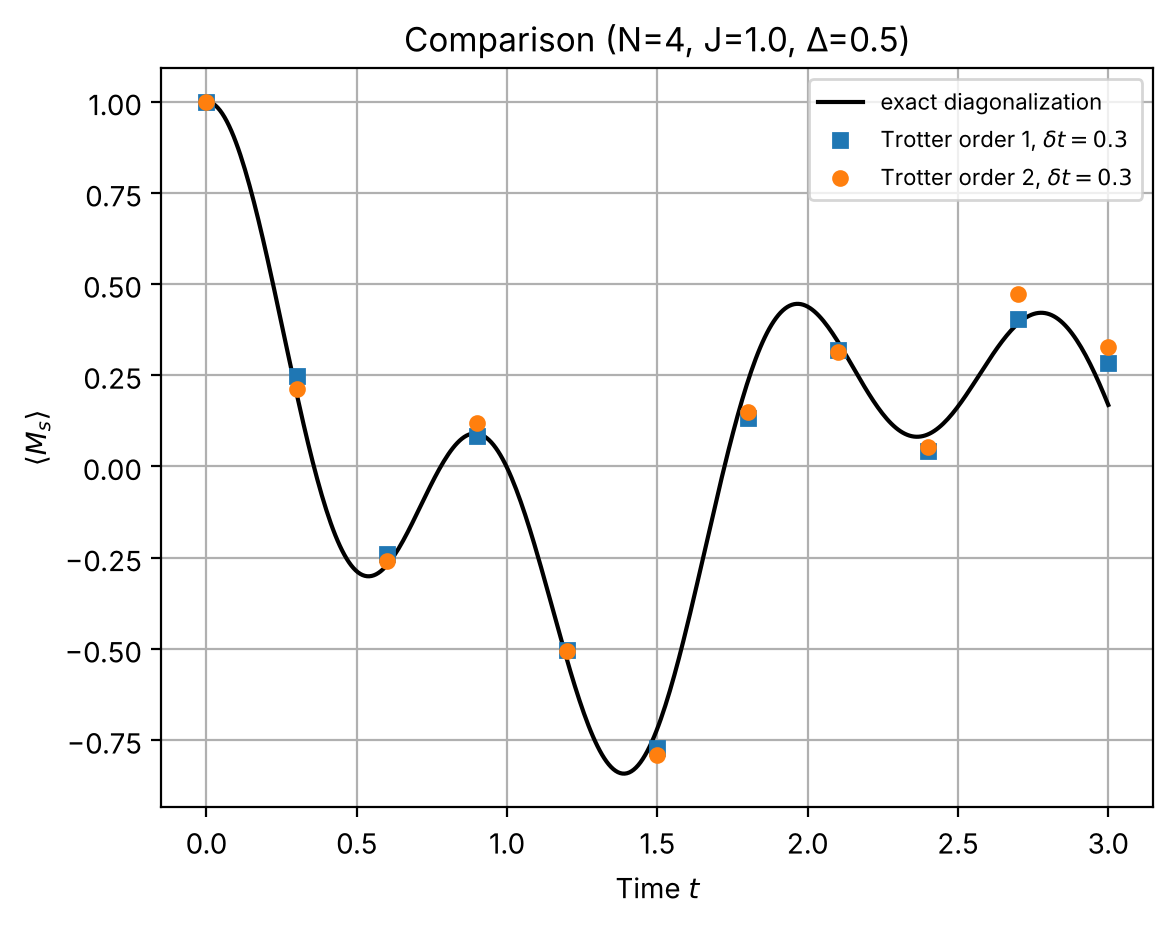

In [4]:
N = 4
H = hamiltonian(N, J, Delta)
ts = np.linspace(0, t_max, 400)
plt.plot(ts, time_evolve_expectation(H, neel_state(N), staggered_magnetization(N), ts), "k-", label="exact diagonalization")
r = 10
for order, mk in [(1, "s"), (2, "o")]:
    ts_r, ms_r = ms_trotter(N, J, Delta, t_max, r, order)
    exact = time_evolve_expectation(H, neel_state(N), staggered_magnetization(N), ts_r)
    print(f"{order}次 (δt = {t_max / r}): 最大誤差 = {np.max(np.abs(ms_r - exact)):.2e}")
    plt.plot(ts_r, ms_r, mk, ms=5, label=rf"Trotter order {order}, $\delta t={t_max / r}$")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J}, Δ={Delta})")
plt.legend(fontsize=8)
plt.grid()
plt.show()

$n=4$では1次と2次の分解の結果が異なる。$\delta t = 0.3$ではどちらも誤差が$0.1$程度あり、この大きさの$\delta t$では2次の方が良いとは限らない（2次の分解は$\delta t\to0$での誤差の減り方が速いという意味で高精度である）。

$n$を大きくしたときの厳密対角化との比較、ステップ数$r$と誤差の関係（1次と2次の比較）、測定のサンプリングによる推定は、[12_staggered_magnetization.ipynb](12_staggered_magnetization.ipynb)で行う。

---
**前へ**: [02 Jordan-Wigner変換とBethe仮説](02_jordan_wigner.ipynb)　｜　**次へ**: [04 VQE](04_vqe.ipynb)